## Importing 

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

os.makedirs('output', exist_ok=True)
np.random.seed(42)
print('Libraries loaded successfully')

Libraries loaded successfully


## Simulating regional service call data

In [2]:
REGIONS = {
    'Northeast': {'base': 420, 'growth': 0.003, 'seasonal_amp': 0.15},
    'Southeast': {'base': 380, 'growth': 0.004, 'seasonal_amp': 0.20},
    'Midwest':   {'base': 310, 'growth': 0.002, 'seasonal_amp': 0.18},
    'Southwest':  {'base': 270, 'growth': 0.005, 'seasonal_amp': 0.12},
    'West':      {'base': 350, 'growth': 0.003, 'seasonal_amp': 0.10},
}

AVG_CALLS_PER_TECH = 18
HOURLY_RATE        = 28.50
HOURS_PER_WEEK     = 40
WEEKLY_COST_PER_TECH = HOURLY_RATE * HOURS_PER_WEEK

weeks = pd.date_range(start='2023-01-02', periods=104, freq='W')
rows  = []

for region, params in REGIONS.items():
    for i, week in enumerate(weeks):
        trend = params['base'] * (1 + params['growth'] * i)

        day_of_year = week.dayofyear
        seasonal = 1 + params['seasonal_amp'] * np.sin(2 * np.pi * (day_of_year - 90) / 365)

        noise = np.random.normal(1.0, 0.06)

        actual_calls = max(0, round(trend * seasonal * noise))

        planned_calls  = round(trend * (1 + params['seasonal_amp'] * 0.5 *
                               np.sin(2 * np.pi * (day_of_year - 90) / 365)))
        planned_techs  = max(1, round(planned_calls / AVG_CALLS_PER_TECH))
        actual_techs   = max(1, round(actual_calls  / AVG_CALLS_PER_TECH))

        rows.append({
            'week':           week,
            'region':         region,
            'actual_calls':   actual_calls,
            'planned_calls':  planned_calls,
            'actual_techs':   actual_techs,
            'planned_techs':  planned_techs,
            'actual_cost':    actual_techs  * WEEKLY_COST_PER_TECH,
            'planned_cost':   planned_techs * WEEKLY_COST_PER_TECH,
        })

df = pd.DataFrame(rows)
df['headcount_variance'] = df['actual_techs']  - df['planned_techs']
df['cost_variance']      = df['actual_cost']   - df['planned_cost']
df['overstaffed']        = df['headcount_variance'] < 0  # planned > actual = overstaffed

print(f'Simulated {len(df):,} weekly records across {len(REGIONS)} regions')
print(f'Date range: {df["week"].min().date()} to {df["week"].max().date()}')
df.head(10)

Simulated 520 weekly records across 5 regions
Date range: 2023-01-08 to 2024-12-29


,week,region,actual_calls,planned_calls,actual_techs,planned_techs,actual_cost,planned_cost,headcount_variance,cost_variance,overstaffed
0,2023-01-08,Northeast,368,389,20,22,22800.0,25080.0,-2,-2280.0,True
1,2023-01-15,Northeast,358,391,20,22,22800.0,25080.0,-2,-2280.0,True
2,2023-01-22,Northeast,378,393,21,22,23940.0,25080.0,-1,-1140.0,True
3,2023-01-29,Northeast,402,396,22,22,25080.0,25080.0,0,0.0,False
4,2023-02-05,Northeast,369,399,20,22,22800.0,25080.0,-2,-2280.0,True
5,2023-02-12,Northeast,375,403,21,22,23940.0,25080.0,-1,-1140.0,True
6,2023-02-19,Northeast,423,407,24,23,27360.0,26220.0,1,1140.0,False
7,2023-02-26,Northeast,412,412,23,23,26220.0,26220.0,0,0.0,False
8,2023-03-05,Northeast,391,416,22,23,25080.0,26220.0,-1,-1140.0,True
9,2023-03-12,Northeast,424,421,24,23,27360.0,26220.0,1,1140.0,False


## Forecasting demand

In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

forecast_rows = []
future_weeks  = pd.date_range(start=df['week'].max() + pd.Timedelta(weeks=1), periods=12, freq='W')

for region in REGIONS:
    region_data = df[df['region'] == region].set_index('week')['actual_calls']

    model  = ExponentialSmoothing(region_data, trend='add', seasonal='add', seasonal_periods=52)
    fitted = model.fit(optimized=True)
    preds  = fitted.forecast(12)

    for week, forecast in zip(future_weeks, preds):
        forecasted_calls = max(0, round(forecast))
        required_techs   = max(1, round(forecasted_calls / AVG_CALLS_PER_TECH))
        forecast_rows.append({
            'week':            week,
            'region':          region,
            'forecasted_calls': forecasted_calls,
            'required_techs':  required_techs,
            'forecasted_cost': required_techs * WEEKLY_COST_PER_TECH,
        })

forecast_df = pd.DataFrame(forecast_rows)

print('12-Week Headcount Forecast by Region:')
summary = forecast_df.groupby('region').agg(
    avg_weekly_calls=('forecasted_calls', 'mean'),
    avg_techs_needed=('required_techs', 'mean'),
    total_12wk_cost=('forecasted_cost', 'sum')
).round(1)
print(summary.to_string())

/Users/a.hage/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/Users/a.hage/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/Users/a.hage/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


12-Week Headcount Forecast by Region:
           avg_weekly_calls  avg_techs_needed  total_12wk_cost
region                                                        
Midwest               314.2              17.6         240540.0
Northeast             525.2              29.2         400140.0
Southeast             507.2              28.2         385320.0
Southwest             401.9              22.3         305520.0
West                  422.8              23.5         321480.0


/Users/a.hage/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/Users/a.hage/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


## Budget variance summary

In [4]:
variance_summary = df.groupby('region').agg(
    total_actual_cost=('actual_cost',      'sum'),
    total_planned_cost=('planned_cost',     'sum'),
    total_cost_variance=('cost_variance',   'sum'),
    overstaffed_weeks=('overstaffed',       'sum'),
    understaffed_weeks=('overstaffed',      lambda x: (~x).sum()),
    avg_headcount_variance=('headcount_variance', 'mean'),
).round(2)

variance_summary['variance_pct'] = (
    (variance_summary['total_cost_variance'] / variance_summary['total_planned_cost']) * 100
).round(2)

print('=== 2-Year Budget Variance Summary ===')
print(variance_summary[['total_planned_cost','total_actual_cost','total_cost_variance','variance_pct','overstaffed_weeks']].to_string())

=== 2-Year Budget Variance Summary ===
           total_planned_cost  total_actual_cost  total_cost_variance  variance_pct  overstaffed_weeks
region                                                                                                
Midwest             2254920.0          2257200.0               2280.0          0.10                 41
Northeast           3193140.0          3170340.0             -22800.0         -0.71                 49
Southeast           3017580.0          3033540.0              15960.0          0.53                 46
Southwest           2238960.0          2241240.0               2280.0          0.10                 39
West                2659620.0          2648220.0             -11400.0         -0.43                 46


## Finding optimization opportunities for overstaffing

In [5]:
overstaffed = df[df['overstaffed']].copy()
wasted_cost = overstaffed.groupby('region')['cost_variance'].sum().abs()

print('=== Cost Optimization Opportunities ===')
print('Estimated recoverable overstaffing cost by region (2 years):')
for region, cost in wasted_cost.sort_values(ascending=False).items():
    weeks_over = len(overstaffed[overstaffed['region'] == region])
    print(f'  {region:<12} ${cost:>10,.0f}  ({weeks_over} overstaffed weeks)')

print(f'\nTotal potential savings: ${wasted_cost.sum():,.0f}')
print(f'\nRecommendation: Implement rolling 4-week demand forecast to adjust staffing')
print(f'rather than fixed quarterly headcount plans. Estimated efficiency gain:')
pct = wasted_cost.sum() / df['planned_cost'].sum() * 100
print(f'  ~{pct:.1f}% reduction in total staffing cost')

=== Cost Optimization Opportunities ===
Estimated recoverable overstaffing cost by region (2 years):
  Northeast    $   111,720  (49 overstaffed weeks)
  Southeast    $   103,740  (46 overstaffed weeks)
  West         $    77,520  (46 overstaffed weeks)
  Midwest      $    74,100  (41 overstaffed weeks)
  Southwest    $    58,140  (39 overstaffed weeks)

Total potential savings: $425,220

Recommendation: Implement rolling 4-week demand forecast to adjust staffing
rather than fixed quarterly headcount plans. Estimated efficiency gain:
  ~3.2% reduction in total staffing cost


## Visualizing results into charts

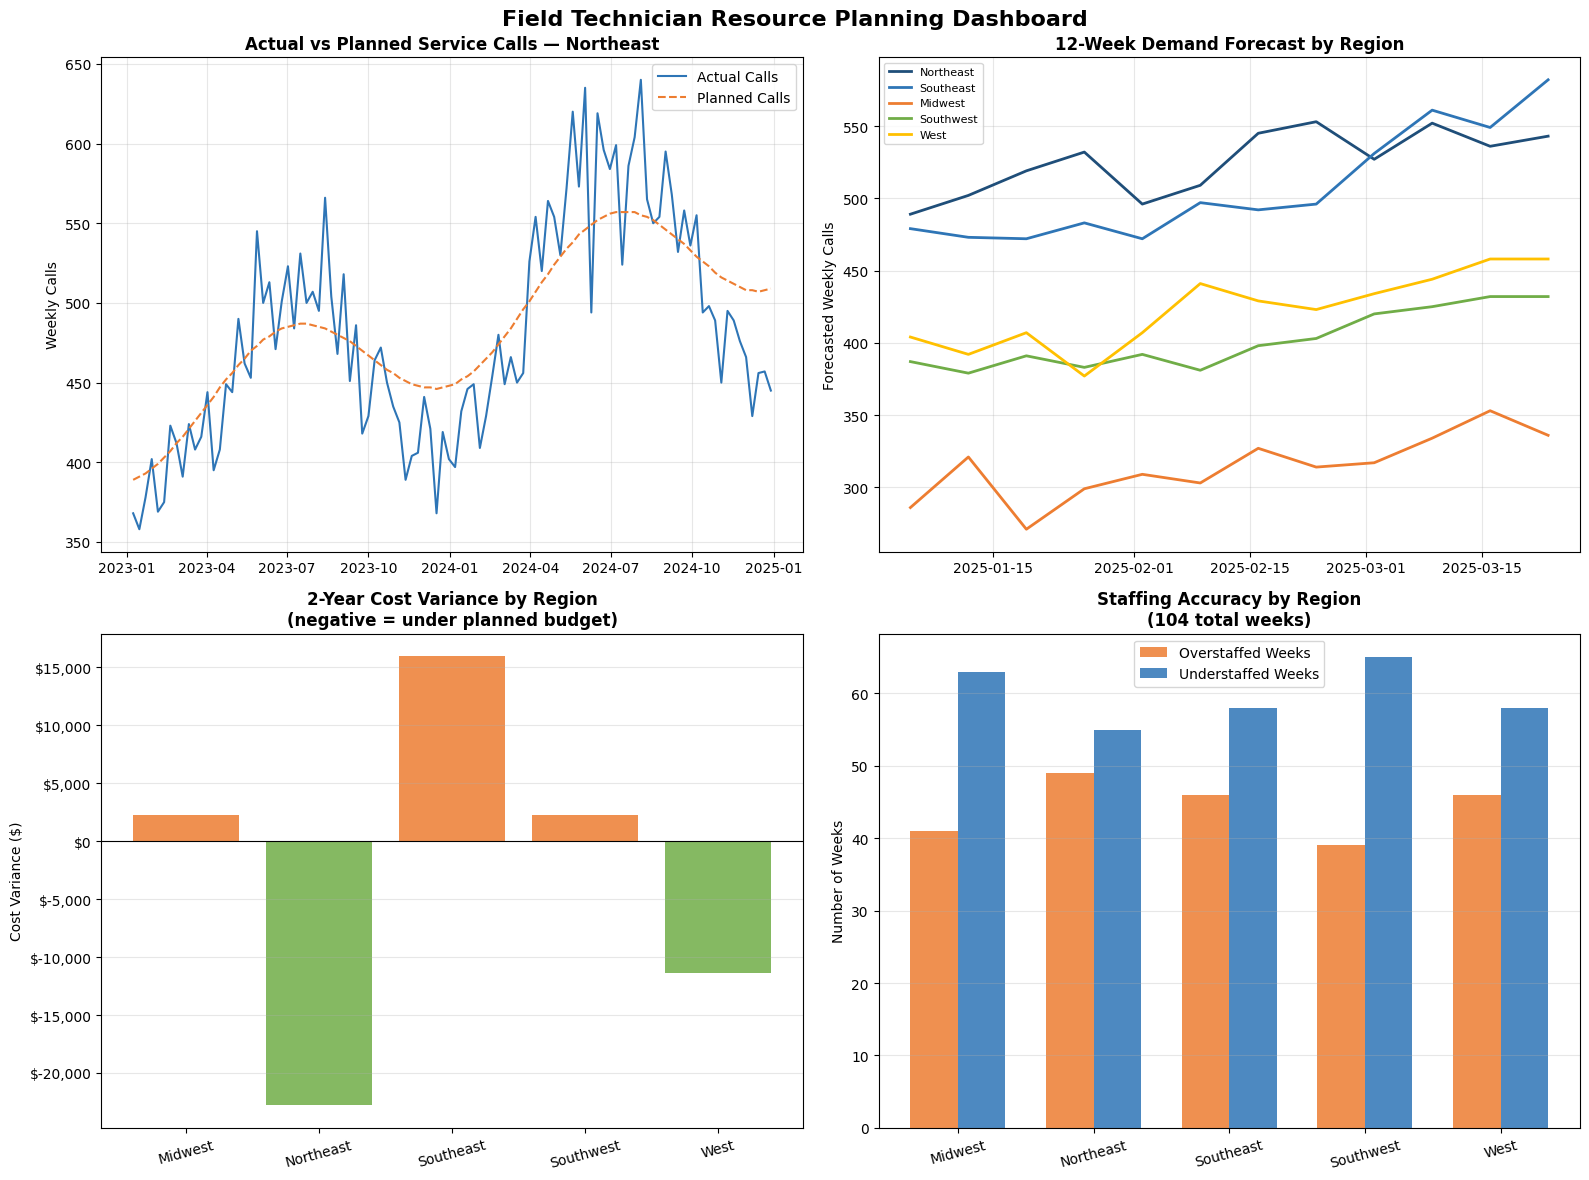

Chart saved to output/headcount_dashboard.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Field Technician Resource Planning Dashboard', fontsize=16, fontweight='bold')

COLORS = ['#1f4e79','#2e75b6','#ed7d31','#70ad47','#ffc000']

ax = axes[0, 0]
ne = df[df['region'] == 'Northeast']
ax.plot(ne['week'], ne['actual_calls'],  label='Actual Calls',  color='#2e75b6', linewidth=1.5)
ax.plot(ne['week'], ne['planned_calls'], label='Planned Calls', color='#ed7d31', linewidth=1.5, linestyle='--')
ax.set_title('Actual vs Planned Service Calls — Northeast', fontweight='bold')
ax.set_ylabel('Weekly Calls')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
for i, region in enumerate(REGIONS):
    rdata = forecast_df[forecast_df['region'] == region]
    ax.plot(rdata['week'], rdata['forecasted_calls'], label=region, color=COLORS[i], linewidth=2)
ax.set_title('12-Week Demand Forecast by Region', fontweight='bold')
ax.set_ylabel('Forecasted Weekly Calls')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
regions_list = variance_summary.index.tolist()
variances    = variance_summary['total_cost_variance'].values
bar_colors   = ['#70ad47' if v < 0 else '#ed7d31' for v in variances]  # green=under budget
bars = ax.bar(regions_list, variances, color=bar_colors, alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('2-Year Cost Variance by Region\n(negative = under planned budget)', fontweight='bold')
ax.set_ylabel('Cost Variance ($)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.tick_params(axis='x', rotation=15)
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1, 1]
x      = np.arange(len(regions_list))
width  = 0.35
over   = variance_summary['overstaffed_weeks'].values
under  = variance_summary['understaffed_weeks'].values
ax.bar(x - width/2, over,  width, label='Overstaffed Weeks',  color='#ed7d31', alpha=0.85)
ax.bar(x + width/2, under, width, label='Understaffed Weeks', color='#2e75b6', alpha=0.85)
ax.set_title('Staffing Accuracy by Region\n(104 total weeks)', fontweight='bold')
ax.set_ylabel('Number of Weeks')
ax.set_xticks(x)
ax.set_xticklabels(regions_list, rotation=15)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('output/headcount_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved to output/headcount_dashboard.png')

## Exporting results to a Tableau dashboard

In [7]:
df.to_csv('output/headcount_historical.csv', index=False)

forecast_df.to_csv('output/headcount_forecast.csv', index=False)

variance_summary.reset_index().to_csv('output/headcount_variance_summary.csv', index=False)

print('Exported:')
print('  output/headcount_historical.csv')
print('  output/headcount_forecast.csv')
print('  output/headcount_variance_summary.csv')
print('  output/headcount_dashboard.png')

Exported:
  output/headcount_historical.csv       <- actual vs planned (2 years)
  output/headcount_forecast.csv         <- 12-week forward forecast
  output/headcount_variance_summary.csv <- regional variance summary
  output/headcount_dashboard.png        <- use in GitHub README
